# pod_shred_nektar

**Question.** Does SHRED do better, or train faster, when it predicts POD coefficients instead of the full field,
as in masked-shred? And does the loss space matter: the decoded field (as SHRED) or the MinMax-scaled coefficients
(as the paper)?

Setup (`configs/experiment/pod_shred_nektar.yaml`, `docs/protocol.md` row *POD SHRED*): Nektar (u, v), 8 QR probes,
clean training and evaluation, 1000 epochs with default early stopping, seeds 0, 1, 2, CPU with 6 workers. POD basis as
in the paper: per field StandardScaler on the training snapshots, SVD, r = 16 / 32 / 64 modes per field (so 2r outputs),
MinMax per coefficient. Same GRU encoder and 350/400 decoder as SHRED; only the output width changes
(10 000 → 2r).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display
from get_shredded.model import PODSHRED
from get_shredded.runner import load_arrays, load_config, load_results, output_root, prepare_seed

cfg = load_config(["+experiment=pod_shred_nektar"])
MAIN = output_root(cfg)
SMOKE = output_root(load_config(["+experiment=pod_shred_nektar", "name=pod_shred_nektar_smoke"]))
RUNS = [f"{r.method}__{r.train}" for r in cfg.runs]

def describe(run):
    m = cfg.methods[run.split("__")[0]]
    if m.kind == "shred":
        return "full field", "–", "field"
    return "POD", str(m.rank), str(m.loss_space)

def seed_table(rt, seeds):
    res = load_results(rt)
    rows = ["| run | output | r / field | loss | test err | err u | err v | train err | val checks (≈ epochs) | wall s | params |",
            "|---|---|---:|---|---:|---:|---:|---:|---:|---:|---:|"]
    for run in RUNS:
        done = [res[(run, s)] for s in seeds if (run, s) in res]
        if not done:
            continue
        def ms(f):
            v = [f(x["metrics"]) for x in done]
            return f"{np.mean(v):.4f} ± {np.std(v):.4f}" if len(v) > 1 else f"{v[0]:.4f}"
        checks = np.mean([x["metrics"]["epochs_used"] for x in done])
        wall = np.mean([x["wall_time_s"] for x in done])
        out, r, loss = describe(run)
        rows.append(f"| {run} | {out} | {r} | {loss} | {ms(lambda m: m['clean']['err'])} | "
                    f"{ms(lambda m: m['none_oracle_p0']['err_u'])} | {ms(lambda m: m['none_oracle_p0']['err_v'])} | "
                    f"{ms(lambda m: m['train']['err'])} | {checks:.1f} (≈ {20 * (checks - 1):.0f}) | {wall:.0f} | "
                    f"{done[0]['metrics']['parameters']:,} |")
    return Markdown("\n".join(rows))

## 1. Smoke runs (seed 0, 20 epochs)

Outputs in `outputs/pod_shred_nektar_smoke/` (wave and Nektar). They only show that every run trains and evaluates.

In [2]:
display(seed_table(SMOKE, [0]))

| run | output | r / field | loss | test err | err u | err v | train err | val checks (≈ epochs) | wall s | params |
|---|---|---:|---|---:|---:|---:|---:|---:|---:|---:|
| shred__clean | full field | – | field | 0.0938 | 0.0518 | 0.2740 | 0.0927 | 2.0 (≈ 20) | 2 | 4,213,854 |
| pod_shred__clean | POD | 16 | field | 0.0579 | 0.0260 | 0.1800 | 0.0594 | 2.0 (≈ 20) | 1 | 216,686 |
| pod_shred_r32__clean | POD | 32 | field | 0.0596 | 0.0285 | 0.1825 | 0.0618 | 2.0 (≈ 20) | 2 | 229,518 |
| pod_shred_r64__clean | POD | 64 | field | 0.0622 | 0.0298 | 0.1902 | 0.0635 | 2.0 (≈ 20) | 2 | 255,182 |
| pod_shred_coef_r16__clean | POD | 16 | coef | 0.1000 | 0.0473 | 0.3071 | 0.0977 | 2.0 (≈ 20) | 1 | 216,686 |
| pod_shred_coef_r32__clean | POD | 32 | coef | 0.1838 | 0.0981 | 0.5440 | 0.1924 | 2.0 (≈ 20) | 1 | 229,518 |
| pod_shred_coef_r64__clean | POD | 64 | coef | 0.2455 | 0.1318 | 0.7250 | 0.2490 | 2.0 (≈ 20) | 1 | 255,182 |

## 2. Projection floor

The best test error any rank-r model can reach: test snapshots projected on the seed's training basis (per field
StandardScaler, r modes per field), in the same relative L2 as `err`. SHRED's full field has no such floor.

In [3]:
floor = {}
for seed in cfg.eval.seeds:
    sd = prepare_seed(cfg, seed)
    m = sd.load_X.shape[1]
    for r in (16, 32, 64):
        pod = PODSHRED(1, sd.load_X[sd.train_idx], sd.channels, r, np.ones(m), np.zeros(m),
                       hidden_size=4, hidden_layers=1, l1=2, l2=2)
        truth = torch.tensor(sd.truth)
        with torch.no_grad():
            proj = pod.decode(pod.coefficient_targets(truth)).numpy()
        floor.setdefault(r, []).append(np.linalg.norm(proj - sd.truth) / np.linalg.norm(sd.truth))
display(Markdown("| r / field | projection floor (mean ± std over seeds) |\n|---:|---:|\n" + "\n".join(
    f"| {r} | {np.mean(v):.1e} ± {np.std(v):.1e} |" for r, v in floor.items())))

| r / field | projection floor (mean ± std over seeds) |
|---:|---:|
| 16 | 2.9e-04 ± 5.2e-06 |
| 32 | 2.4e-06 ± 4.7e-08 |
| 64 | 1.6e-06 ± 8.3e-08 |

## 3. Full runs, 3 seeds (mean ± std)

In [4]:
display(seed_table(MAIN, list(cfg.eval.seeds)))

| run | output | r / field | loss | test err | err u | err v | train err | val checks (≈ epochs) | wall s | params |
|---|---|---:|---|---:|---:|---:|---:|---:|---:|---:|
| shred__clean | full field | – | field | 0.0021 ± 0.0003 | 0.0011 ± 0.0001 | 0.0064 ± 0.0008 | 0.0017 ± 0.0002 | 36.7 (≈ 713) | 43 | 4,213,854 |
| pod_shred__clean | POD | 16 | field | 0.0025 ± 0.0003 | 0.0013 ± 0.0002 | 0.0076 ± 0.0009 | 0.0022 ± 0.0001 | 25.3 (≈ 487) | 12 | 216,686 |
| pod_shred_r32__clean | POD | 32 | field | 0.0027 ± 0.0003 | 0.0014 ± 0.0002 | 0.0081 ± 0.0007 | 0.0025 ± 0.0002 | 26.7 (≈ 513) | 14 | 229,518 |
| pod_shred_r64__clean | POD | 64 | field | 0.0028 ± 0.0008 | 0.0014 ± 0.0004 | 0.0085 ± 0.0024 | 0.0026 ± 0.0007 | 23.7 (≈ 453) | 13 | 255,182 |
| pod_shred_coef_r16__clean | POD | 16 | coef | 0.0028 ± 0.0002 | 0.0014 ± 0.0002 | 0.0084 ± 0.0003 | 0.0022 ± 0.0004 | 21.7 (≈ 413) | 8 | 216,686 |
| pod_shred_coef_r32__clean | POD | 32 | coef | 0.0106 ± 0.0021 | 0.0050 ± 0.0016 | 0.0322 ± 0.0059 | 0.0087 ± 0.0014 | 24.3 (≈ 467) | 8 | 229,518 |
| pod_shred_coef_r64__clean | POD | 64 | coef | 0.0197 ± 0.0036 | 0.0100 ± 0.0014 | 0.0594 ± 0.0116 | 0.0182 ± 0.0042 | 21.3 (≈ 407) | 7 | 255,182 |
| pod_trunk_shred__clean | POD | 16 | field | 0.0077 ± 0.0003 | 0.0052 ± 0.0001 | 0.0202 ± 0.0008 | 0.0076 ± 0.0003 | 21.3 (≈ 407) | 141 | 216,686 |
| pod_trunk_shred_coef__clean | POD | 16 | coef | 0.0098 ± 0.0012 | 0.0062 ± 0.0002 | 0.0267 ± 0.0047 | 0.0088 ± 0.0007 | 13.0 (≈ 240) | 136 | 216,686 |
| pod_trunk_shred_div__clean | POD | 16 | field | 0.0074 ± 0.0000 | 0.0051 ± 0.0000 | 0.0191 ± 0.0001 | 0.0073 ± 0.0001 | 32.7 (≈ 633) | 210 | 216,686 |
| pod_trunk_shred_train__clean | POD | 16 | field | 0.0067 ± 0.0008 | 0.0038 ± 0.0004 | 0.0193 ± 0.0022 | 0.0066 ± 0.0008 | 20.3 (≈ 387) | 182 | 308,370 |
| pod_trunk_shred_train_div__clean | POD | 16 | field | 0.0068 ± 0.0013 | 0.0038 ± 0.0006 | 0.0197 ± 0.0039 | 0.0066 ± 0.0012 | 21.0 (≈ 400) | 231 | 308,370 |

**Result (3 seeds, mean ± std).** Test error: SHRED (full field) **0.0021 ± 0.0003**. POD, field loss: r = 16 0.0025 ±
0.0003, r = 32 0.0027 ± 0.0003, r = 64 0.0028 ± 0.0008. POD, coefficient loss: r = 16 0.0028 ± 0.0002, r = 32
**0.0106 ± 0.0021**, r = 64 **0.0197 ± 0.0036**. The projection floor (section 2) is 3e-4 at r = 16 and below 1e-5 from
r = 32, so the basis never limits any run: the gaps are training, not truncation. Train error tracks test error in every
run (no overfitting). v is ≈ 6× worse than u in every run.

Speed: the POD models have 217k–255k parameters against SHRED's 4.2M (the 400 → 10 000 output layer), and take
12–14 s per run (field loss) and 7–8 s (coefficient loss) against 43 s, with 6 runs sharing the CPU. Per epoch that is
≈ 0.025 s against ≈ 0.060 s (≈ 2.4×). The POD runs also early-stop sooner (≈ 410–510 epochs against ≈ 710).

## 4. Validation curves

`val_history`: validation relative L2 at epoch 1 and every 20 epochs. For the `coef` runs it is measured on the scaled
coefficients (their early-stopping criterion), so their curves are not on the same scale as the field runs.

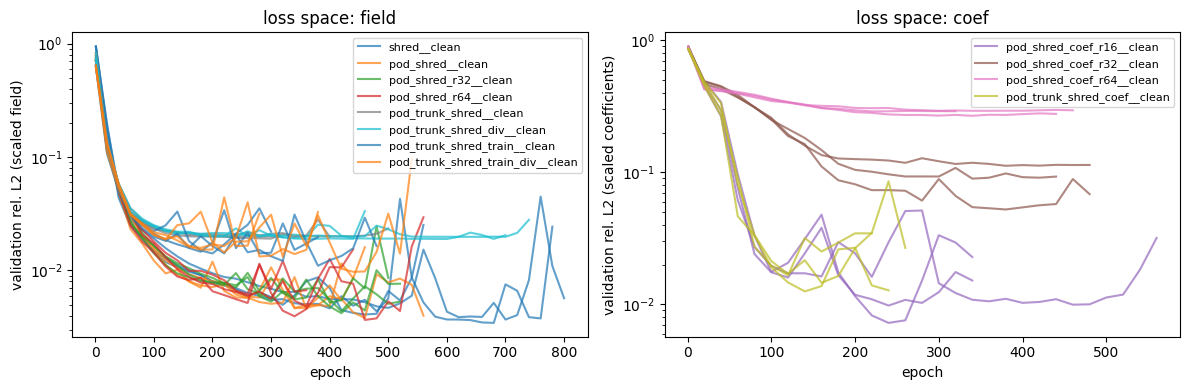

In [5]:
res = load_results(MAIN)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, space in zip(axes, ("field", "coef")):
    for i, run in enumerate(RUNS):
        if describe(run)[2] != space:
            continue
        for s in cfg.eval.seeds:
            if (run, s) not in res:
                continue
            h = load_arrays(MAIN, run, s)["val_history"]
            ax.semilogy(np.r_[1, 20 * np.arange(1, len(h))], h, color=f"C{i}", alpha=0.7,
                        label=run if s == cfg.eval.seeds[0] else None)
    ax.set(xlabel="epoch", ylabel="validation rel. L2 (" + ("scaled field" if space == "field" else "scaled coefficients") + ")",
           title=f"loss space: {space}")
    ax.legend(fontsize=8)
plt.tight_layout()

## 5. POD trunk SHRED: frozen vs trained trunk

POD SHRED at r = 16 whose basis (per-field mean, std and the 16 modes per field) is a small network T(x, y), so the
field can be differentiated anywhere and the continuity residual u_x + v_y can enter the loss. The trunk is first
fitted to the grid basis (values only, 5000 Adam steps). Then either

- **frozen** (`pod_trunk_shred`, `_coef`, `_div`): SHRED trains only the coefficients; or
- **trained** (`pod_trunk_shred_train`, `_train_div`): the trunk keeps training with SHRED (same optimiser, lr 1e-3),
  so the field loss and the continuity loss can also reshape the basis.

`_div` runs add λ = 1e-3 × mean (u_x + v_y)² on 64 random points per sample. `div_rel` = rms divergence / rms |∇u| of
the clean test predictions (autograd through the trunk); the data's own finite-difference value is ≈ 0.003.

In [6]:
TRUNK_RUNS = [r for r in RUNS if cfg.methods[r.split("__")[0]].kind == "pod_trunk_shred"]

def trunk_table(rt, seeds):
    res = load_results(rt)
    rows = ["| run | trunk | loss | λ | test err | err u | err v | train err | val checks | wall s | div_rel (held out) |",
            "|---|---|---|---:|---:|---:|---:|---:|---:|---:|---:|"]
    for run in TRUNK_RUNS:
        done = [res[(run, s)]["metrics"] for s in seeds if (run, s) in res]
        if not done:
            continue
        ms = lambda f: f"{np.mean([f(x) for x in done]):.4f} ± {np.std([f(x) for x in done]):.4f}"
        m = cfg.methods[run.split("__")[0]]
        wall = np.mean([res[(run, s)]["wall_time_s"] for s in seeds if (run, s) in res])
        rows.append(f"| {run} | {'trained' if m.get('train_trunk', False) else 'frozen'} | {m.loss_space} | "
                    f"{m.physics_weight:g} | {ms(lambda x: x['clean']['err'])} | {ms(lambda x: x['none_oracle_p0']['err_u'])} | "
                    f"{ms(lambda x: x['none_oracle_p0']['err_v'])} | {ms(lambda x: x['train']['err'])} | "
                    f"{np.mean([x['epochs_used'] for x in done]):.1f} | {wall:.0f} | {ms(lambda x: x['div_rel']['held_out'])} |")
    return Markdown("\n".join(rows))

display(trunk_table(MAIN, list(cfg.eval.seeds)))

| run | trunk | loss | λ | test err | err u | err v | train err | val checks | wall s | div_rel (held out) |
|---|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| pod_trunk_shred__clean | frozen | field | 0 | 0.0077 ± 0.0003 | 0.0052 ± 0.0001 | 0.0202 ± 0.0008 | 0.0076 ± 0.0003 | 21.3 | 141 | 0.1256 ± 0.0038 |
| pod_trunk_shred_coef__clean | frozen | coef | 0 | 0.0098 ± 0.0012 | 0.0062 ± 0.0002 | 0.0267 ± 0.0047 | 0.0088 ± 0.0007 | 13.0 | 136 | 0.1257 ± 0.0037 |
| pod_trunk_shred_div__clean | frozen | field | 0.001 | 0.0074 ± 0.0000 | 0.0051 ± 0.0000 | 0.0191 ± 0.0001 | 0.0073 ± 0.0001 | 32.7 | 210 | 0.1256 ± 0.0038 |
| pod_trunk_shred_train__clean | trained | field | 0 | 0.0067 ± 0.0008 | 0.0038 ± 0.0004 | 0.0193 ± 0.0022 | 0.0066 ± 0.0008 | 20.3 | 182 | 0.1015 ± 0.0049 |
| pod_trunk_shred_train_div__clean | trained | field | 0.001 | 0.0068 ± 0.0013 | 0.0038 ± 0.0006 | 0.0197 ± 0.0039 | 0.0066 ± 0.0012 | 21.0 | 231 | 0.0946 ± 0.0123 |

### 5a. Where the error and the divergence come from

Per trained model (weights from `model.pt`), on the test snapshots of its seed:

- **basis floor**: the test truth's exact POD coefficients decoded through the model's trunk basis at the grid. The
  exact grid basis gives the projection floor of section 2 (≈ 3e-4 at r = 16); anything above it is trunk misfit.
- **basis div_rel**: div_rel of that floor field (autograd), i.e. the divergence of the basis itself.
- **mean-field div_rel**: div_rel of the trunk's mean field alone (all coefficients zero).
- **removable**: the fraction of the mean field's rms divergence that the best coefficients (least squares, the
  divergence is linear in them) can cancel. Near 0 means no choice of coefficients can make the field divergence free.
- **FD div_rel**: the same ratio by finite differences of the floor field on the grid (truth ≈ 0.003).
- **mode / mean error**: relative distance of the trunk's grid modes and mean field from the exact ones (drift, for
  a trained trunk).

In [7]:
from omegaconf import OmegaConf
from get_shredded.corruption import CorruptionSpec
from get_shredded.runner import _build_model

def load_trunk_model(sd, run, seed):
    m = OmegaConf.merge(cfg.methods[run.split("__")[0]], {"fit_steps": 1})  # weights come from model.pt
    model = _build_model(sd, m, "cpu", cfg.data)
    model.load_state_dict(torch.load(MAIN / f"seed{seed}" / run / "model.pt", map_location="cpu"))
    return model.eval()

def grads(model, a):
    """(gu, gv) of the trunk field mean + std * modes . a at the grid, a: (B, C, r) physical coefficients."""
    xy = model.coords.expand(len(a), -1, -1).clone().requires_grad_()
    T = model.basis_at(xy)
    uv = T[..., 0] + T[..., 1] * torch.einsum("bcr,bqcr->bqc", a, T[..., 2:]) / model.points**0.5
    gu = torch.autograd.grad(uv[..., 0].sum(), xy, retain_graph=True)[0]
    return gu, torch.autograd.grad(uv[..., 1].sum(), xy)[0]

drel = lambda gu, gv: float((gu[..., 0] + gv[..., 1]).square().mean().sqrt() / (gu.square().sum(-1) + gv.square().sum(-1)).mean().sqrt())

def fd_drel(field, xs, ys, P):
    u, v = (field[:, k * P:(k + 1) * P].reshape(-1, len(xs), len(ys)) for k in (0, 1))  # x-major, y fastest
    ux, uy = np.gradient(u, xs, ys, axis=(1, 2)); vx, vy = np.gradient(v, xs, ys, axis=(1, 2))
    d, g = (ux + vy)[:, 1:-1, 1:-1], (ux**2 + uy**2 + vx**2 + vy**2)[:, 1:-1, 1:-1]
    return float(np.sqrt((d**2).mean() / g.mean()))

diag = {}
for seed in cfg.eval.seeds:
    sd = prepare_seed(cfg, seed)
    xs, ys = np.unique(sd.point_coordinates[:, 0]), np.unique(sd.point_coordinates[:, 1])
    assert np.allclose(sd.point_coordinates.reshape(len(xs), len(ys), 2)[:, 0, 0], xs)
    truth = torch.tensor(sd.truth, dtype=torch.float32)
    diag[("truth", seed)] = {"fd": fd_drel(sd.truth, xs, ys, sd.n_points)}
    for run in TRUNK_RUNS:
        if not (MAIN / f"seed{seed}" / run / "model.pt").exists():
            continue
        model = load_trunk_model(sd, run, seed); C, r, P = model.channels, model.rank, model.points
        a = torch.einsum("bcp,crp->bcr", ((truth - model.mean) / model.std).view(-1, C, P), model.Vt)
        with torch.no_grad():
            modes, std, mean = model.grid_basis()
            floor_field = (torch.einsum("bcr,crp->bcp", a, modes).flatten(1) * std + mean).numpy()
        e = torch.cat([torch.zeros(1, C * r), torch.eye(C * r)]).view(-1, C, r)  # div is linear in a: d0 + D a
        gu, gv = grads(model, e); d = (gu[..., 0] + gv[..., 1]).detach()
        d0, D = d[0], (d[1:] - d[0]).T
        best = d0 + D @ torch.linalg.lstsq(D, -d0[:, None]).solution[:, 0]
        diag[(run, seed)] = {
            "floor": float(np.linalg.norm(floor_field - sd.truth) / np.linalg.norm(sd.truth)),
            "basis_div": drel(*grads(model, a)), "mean_div": drel(gu[:1], gv[:1]),
            "removable": 1 - float(best.square().mean().sqrt() / d0.square().mean().sqrt()),
            "fd": fd_drel(floor_field, xs, ys, P),
            "mode_err": float((torch.linalg.norm(modes - model.Vt, dim=-1)).mean()),
            "mean_err": float(torch.linalg.norm(mean - model.mean) / torch.linalg.norm(model.mean)),
        }

keys = ["floor", "basis_div", "mean_div", "removable", "fd", "mode_err", "mean_err"]
rows = ["| run | basis floor | basis div_rel | mean-field div_rel | removable | FD div_rel | mode error | mean error |",
        "|---|---:|---:|---:|---:|---:|---:|---:|",
        f"| data (truth) | – | – | – | – | {np.mean([diag[('truth', s)]['fd'] for s in cfg.eval.seeds]):.4f} | – | – |"]
for run in TRUNK_RUNS:
    got = [diag[(run, s)] for s in cfg.eval.seeds if (run, s) in diag]
    if got:
        rows.append(f"| {run} | " + " | ".join(f"{np.mean([g[k] for g in got]):.4f}" for k in keys) + " |")
display(Markdown("Mean over seeds.\n\n" + "\n".join(rows)))

Mean over seeds.

| run | basis floor | basis div_rel | mean-field div_rel | removable | FD div_rel | mode error | mean error |
|---|---:|---:|---:|---:|---:|---:|---:|
| data (truth) | – | – | – | – | 0.0032 | – | – |
| pod_trunk_shred__clean | 0.0071 | 0.1322 | 0.1190 | 0.0072 | 0.0851 | 0.0186 | 0.0043 |
| pod_trunk_shred_coef__clean | 0.0071 | 0.1322 | 0.1190 | 0.0072 | 0.0851 | 0.0186 | 0.0043 |
| pod_trunk_shred_div__clean | 0.0071 | 0.1322 | 0.1190 | 0.0072 | 0.0851 | 0.0186 | 0.0043 |
| pod_trunk_shred_train__clean | 0.0623 | 0.1160 | 0.0903 | 0.1531 | 0.0842 | 0.2653 | 0.0158 |
| pod_trunk_shred_train_div__clean | 0.0622 | 0.1103 | 0.0870 | 0.1689 | 0.0816 | 0.2689 | 0.0151 |

**Frozen trunk (3 seeds).** Test error: field loss **0.0077 ± 0.0002**, coefficient loss 0.0098 ± 0.0012, field loss +
continuity 0.0074 ± 0.0000, against 0.0025 for POD SHRED with the exact basis (section 3). The frozen trunk's basis
floor is ≈ 0.007, so ≈ 90 % of that error is trunk misfit, not training; more than half of it is the mean field
(u is mostly mean flow). The coefficient loss is worse because it targets the exact coefficients, which the misfit
basis decodes wrongly; the field loss can bend the coefficients to compensate. The values fit to ≈ 0.5 %, but the
trunk's gradients are ≈ 10 % off, so its divergence is ≈ 0.13 (autograd) / ≈ 0.08 (FD) against the data's 0.003, and
most of it sits in the mean field. With the trunk frozen the best coefficients cancel ≈ 0.7 % of it ("removable"), so
the continuity loss cannot act: div_rel is the same in all three frozen runs, and the small error gain of `_div` is
more plausibly weak shrinkage of the coefficients than physics.

**Trained trunk (3 seeds).** Letting the trunk train with SHRED lowers the test error from 0.0077 ± 0.0003 (frozen)
to **0.0067 ± 0.0008**, with or without continuity (0.0068 ± 0.0013), still well above POD SHRED's 0.0025. The gain
is in u (0.0052 → 0.0038); v is unchanged. The divergence drops a little: div_rel 0.126 (frozen) → 0.102 (trained) →
0.095 ± 0.012 (trained + continuity), still ≈ 30× the data's 0.003, and the FD value on the grid stays ≈ 0.08. Most of
the drop comes from training the trunk at all; the continuity term adds ≈ 7 %, within the seed spread, so not
established. The trunk moves a long way from POD (mode error 0.019 → 0.27, basis floor 0.007 → 0.062): SHRED and the
trunk re-parameterise the basis together, so the exact POD coefficients no longer fit it and the "basis floor" column
is not a floor for these runs. Early stopping (on the field error) stops them after ≈ 20 checks (≈ 400 epochs), as
for the frozen runs, so the trunk gets few updates, and λ = 1e-3 makes the continuity term ≈ 7 % of the loss.
Unfreezing alone does not make the physics work: the divergence stays mostly in place. Untested levers: larger λ,
longer training without early stopping, or a derivative-aware initial fit.


**Conclusion (tentative).** Predicting POD coefficients with the loss on the decoded field is ≈ 3× cheaper per run and
≈ 20 % less accurate than SHRED's full-field output (0.0025 vs 0.0021, about one seed std apart); rank barely matters
because the Nektar wake is nearly exactly rank ≤ 32 per field. With the paper's loss (MinMax-scaled coefficients), the
accuracy depends strongly on the rank: at r = 16 it matches the field loss, but every extra mode beyond the flow's real
rank carries almost no energy and is still scaled to [0, 1], so it weighs as much in the loss as the dominant modes,
and the energetic modes are underfit (train error 0.018 at r = 64). That weighting is a property of the paper's pipeline,
and it is most harmful here because the data are so low-rank; on richer data (their HYDRO, SST) the extra modes carry
real signal. Speed rankings: the output layer, not the encoder, sets SHRED's cost per epoch on this setup. Clean data
only; robustness to faults is not tested.